# Final Project: Unsupervised Learning

In this final project I bring together the main unsupervised methods from this course and use them on five different real datasets. There is one task per dataset:

1. **Task 1: Wholesale Customers.** I find and optimize natural customer groups and compare five clustering algorithms.
2. **Task 2: Forest Cover Type.** I use non-linear (spectral) and hierarchical clustering on terrain data.
3. **Task 3: Car Evaluation.** I give soft labels with Fuzzy C-means and a Gaussian Mixture Model.
4. **Task 4: Gas Sensor Array Drift.** I use density estimation to detect anomalies (sensor drift over 36 months).
5. **Task 5: Human Activity Recognition.** I compare PCA (Principal Component Analysis) with linear and non-linear autoencoders (neural networks).

Labels exist in some datasets, but I never use them to fit a model. I only use them at the end to check whether the groups I found make sense.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, Birch, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors, KernelDensity
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.datasets import load_svmlight_file
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, mean_squared_error)

import keras
from keras import layers

pd.set_option("display.max_columns", None)
print("Keras version:", keras.__version__)

Keras version: 3.15.1


# Task 1: Finding and Optimizing Natural Groups (Wholesale Customers)

## About the dataset
The Wholesale Customers dataset has the yearly spending (in monetary units) of 440 clients of a wholesale distributor in Portugal. It has 6 spending categories: Fresh, Milk, Grocery, Frozen, Detergents_Paper and Delicassen. It also has two label-like columns, Channel (1 = Horeca, which means hotels, restaurants and cafés, and 2 = Retail) and Region.

## Goal
I want to find natural customer groups using only the spending columns. I will optimize the number of clusters and compare five algorithms: K-means, Agglomerative (Ward), Gaussian Mixture Model (GMM), DBSCAN and BIRCH.

## Step 1.1: Load the data

In [2]:
ws_df = pd.read_csv("wholesale_customers.csv")
print(ws_df.shape)
ws_df.head()

(440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## Step 1.2: Summary statistics and missing values

In [3]:
print("Missing values:", ws_df.isna().sum().sum())
ws_df.describe().round(0)

Missing values: 0


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.0,440.0,440.0,440.0,440.0,440.0,440.0,440.0
mean,1.0,3.0,12000.0,5796.0,7951.0,3072.0,2881.0,1525.0
std,0.0,1.0,12647.0,7380.0,9503.0,4855.0,4768.0,2820.0
min,1.0,1.0,3.0,55.0,3.0,25.0,3.0,3.0
25%,1.0,2.0,3128.0,1533.0,2153.0,742.0,257.0,408.0
50%,1.0,3.0,8504.0,3627.0,4756.0,1526.0,816.0,966.0
75%,2.0,3.0,16934.0,7190.0,10656.0,3554.0,3922.0,1820.0
max,2.0,3.0,112151.0,73498.0,92780.0,60869.0,40827.0,47943.0


### Interpretation: data exploration
- I have 440 customers and 8 columns, with no missing values.
- The spending columns are very **right-skewed**. For example, Fresh has a median of 8,504 but a maximum of 112,151, and Delicassen has a median of 966 but a maximum of 47,943. A few very big customers would control distance-based clustering.
- Because of this, I use a **log transform** (`log1p`) before scaling, the same as in Assignment 4. I drop Channel and Region from the features and keep Channel only to check my clusters at the end.

## Step 1.3: Preprocess (log transform + scaling)

In [4]:
spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
X_ws = StandardScaler().fit_transform(np.log1p(ws_df[spend_cols]))
y_ws = ws_df["Channel"]   # only used at the end to check the clusters
print(X_ws.shape)

(440, 6)


## Step 1.4: K-means for k = 2 to 10

In [5]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_ws)
    labels = km.labels_
    rows.append([k, km.inertia_, silhouette_score(X_ws, labels),
                 calinski_harabasz_score(X_ws, labels), davies_bouldin_score(X_ws, labels)])
km_scores = pd.DataFrame(rows, columns=["k", "inertia", "silhouette", "calinski_harabasz", "davies_bouldin"])
km_scores.round(3)

,k,inertia,silhouette,calinski_harabasz,davies_bouldin
0,2,1844.064,0.290,189.050,1.352
1,3,1553.421,0.259,152.835,1.341
2,4,1386.863,0.188,131.320,1.541
3,5,1266.149,0.192,118.000,1.484
4,6,1174.759,0.201,108.263,1.432
5,7,1086.359,0.196,103.208,1.392
6,8,1028.486,0.185,96.699,1.441
7,9,973.141,0.197,92.281,1.383
8,10,931.998,0.191,87.559,1.344


## Step 1.5: Plot the four K-means scores

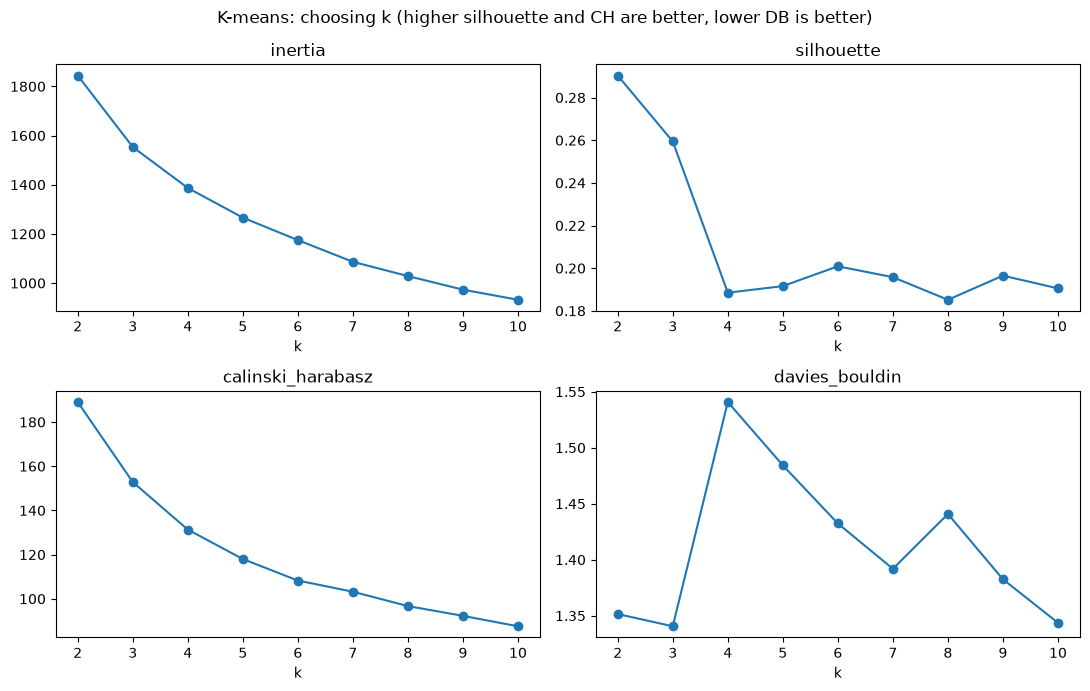

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), ["inertia", "silhouette", "calinski_harabasz", "davies_bouldin"]):
    ax.plot(km_scores["k"], km_scores[col], marker="o")
    ax.set_title(col)
    ax.set_xlabel("k")
plt.suptitle("K-means: choosing k (higher silhouette and CH are better, lower DB is better)")
plt.tight_layout()
plt.show()

### Interpretation: choosing k for K-means
- **Inertia** (elbow method) goes down smoothly with no sharp elbow, so on its own it does not give a clear k.
- **Silhouette** is highest at k = 2 (0.290), then drops to 0.259 at k = 3 and below 0.20 from k = 4.
- **Calinski-Harabasz (CH)** is also highest at k = 2 (189.1).
- **Davies-Bouldin (DB)** is lowest at k = 3 (1.341), but k = 2 is almost the same (1.352).
- Three of the four scores point to **k = 2**, so I use 2 clusters. The silhouette of 0.29 tells me the groups are real but overlap a lot. Customers do not fall into perfectly separate boxes.

## Step 1.6: Final K-means with k = 2

In [7]:
km_labels = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X_ws)
print("Cluster sizes:", np.bincount(km_labels))

Cluster sizes: [252 188]


## Step 1.7: Agglomerative clustering (Ward) for k = 2 to 6

In [8]:
for k in range(2, 7):
    labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_ws)
    print(k, round(silhouette_score(X_ws, labels), 3), np.bincount(labels))

2 0.258 [178 262]
3 0.255 [262  53 125]
4 0.202 [ 53 208 125  54]
5 0.203 [208  18 125  54  35]
6 0.171 [125  18 150  54  35  58]


In [9]:
agg_labels = AgglomerativeClustering(n_clusters=2, linkage="ward").fit_predict(X_ws)

## Step 1.8: GMM with BIC and AIC for 1 to 8 components

In [10]:
rows = []
for k in range(1, 9):
    gmm = GaussianMixture(n_components=k, n_init=5, random_state=42).fit(X_ws)
    rows.append([k, gmm.bic(X_ws), gmm.aic(X_ws)])
gmm_scores = pd.DataFrame(rows, columns=["k", "BIC", "AIC"])
gmm_scores.round(0)

,k,BIC,AIC
0,1,6596.0,6486.0
1,2,6434.0,6210.0
2,3,6442.0,6102.0
3,4,6304.0,5850.0
4,5,6414.0,5846.0
5,6,6515.0,5833.0
6,7,6605.0,5808.0
7,8,6646.0,5734.0


## Step 1.9: Plot BIC and AIC

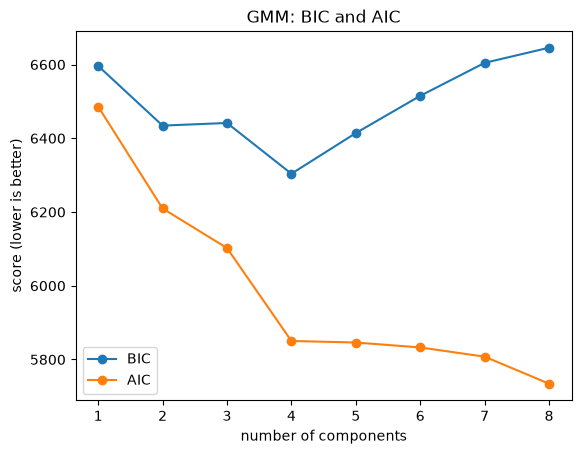

In [11]:
plt.plot(gmm_scores["k"], gmm_scores["BIC"], marker="o", label="BIC")
plt.plot(gmm_scores["k"], gmm_scores["AIC"], marker="o", label="AIC")
plt.xlabel("number of components")
plt.ylabel("score (lower is better)")
plt.title("GMM: BIC and AIC")
plt.legend()
plt.show()

In [12]:
gmm_labels = GaussianMixture(n_components=2, n_init=5, random_state=42).fit(X_ws).predict(X_ws)
print("Cluster sizes:", np.bincount(gmm_labels))

Cluster sizes: [166 274]


### Interpretation: Agglomerative and GMM
- **Agglomerative (Ward)** also gives its best silhouette at k = 2 (0.258), so I keep 2 clusters (178 and 262 customers).
- For the **GMM (Gaussian Mixture Model)**, **BIC (Bayesian Information Criterion)** drops from 6,596 at k = 1 to 6,434 at k = 2. Its lowest value is 6,304 at k = 4, but it then goes back up. **AIC (Akaike Information Criterion)** keeps going down all the way to k = 8, because it punishes extra components less than BIC does.
- Because BIC jumps around after k = 2 and the other methods agree on 2 groups, I use **2 components** so all algorithms can be compared fairly. The GMM gives 166 and 274 customers.

## Step 1.10: DBSCAN: k-distance plot to choose eps

In [13]:
min_samples = 12   # about 2 x number of features
dist, _ = NearestNeighbors(n_neighbors=min_samples).fit(X_ws).kneighbors(X_ws)
k_dist = np.sort(dist[:, -1])

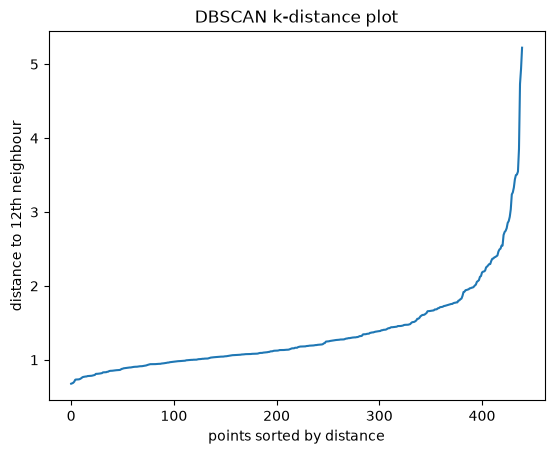

In [14]:
plt.plot(k_dist)
plt.xlabel("points sorted by distance")
plt.ylabel(f"distance to {min_samples}th neighbour")
plt.title("DBSCAN k-distance plot")
plt.show()

## Step 1.11: DBSCAN with different eps values

In [15]:
for eps in [1.0, 1.2, 1.4, 1.6, 1.8, 2.0]:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_ws)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    print(f"eps={eps}: clusters={n_clusters}, noise points={(labels == -1).sum()}")

eps=1.0: clusters=1, noise points=183
eps=1.2: clusters=1, noise points=105
eps=1.4: clusters=1, noise points=67
eps=1.6: clusters=1, noise points=42
eps=1.8: clusters=1, noise points=27
eps=2.0: clusters=1, noise points=17


In [16]:
db_labels = DBSCAN(eps=1.6, min_samples=min_samples).fit_predict(X_ws)

### Interpretation: DBSCAN
- The k-distance plot rises slowly with no sharp knee, then bends up at the end (about 1.6–2.0).
- For every eps value I tried, DBSCAN finds **only 1 cluster plus noise points**. With eps = 1.6, there are 42 noise points (about 10% of customers).
- This means the data is **one dense cloud** with no empty gap between groups. DBSCAN needs low-density gaps, so it cannot split Horeca and Retail. It is still useful, because the 42 noise points are the unusual customers (very high or very low spending).
- Since DBSCAN gives only one cluster, I cannot compute a silhouette score for it, so I leave it out of the score table.

## Step 1.12: BIRCH with 2 clusters

In [17]:
birch_labels = Birch(n_clusters=2).fit_predict(X_ws)
print("Cluster sizes:", np.bincount(birch_labels))

Cluster sizes: [235 205]


## Step 1.13: Compare all algorithms

In [18]:
results = {"K-means": km_labels, "Agglomerative (Ward)": agg_labels, "GMM": gmm_labels, "BIRCH": birch_labels}
rows = []
for name, labels in results.items():
    rows.append([name, np.bincount(labels).tolist(), silhouette_score(X_ws, labels),
                 calinski_harabasz_score(X_ws, labels), davies_bouldin_score(X_ws, labels),
                 adjusted_rand_score(y_ws, labels)])
compare_ws = pd.DataFrame(rows, columns=["algorithm", "sizes", "silhouette", "calinski_harabasz",
                                         "davies_bouldin", "ARI_vs_Channel"])
compare_ws.round(3)

,algorithm,sizes,silhouette,calinski_harabasz,davies_bouldin,ARI_vs_Channel
0,K-means,"[252, 188]",0.290,189.050,1.352,0.514
1,Agglomerative (Ward),"[178, 262]",0.258,134.624,1.600,0.539
2,GMM,"[166, 274]",0.266,165.420,1.391,0.622
3,BIRCH,"[235, 205]",0.222,123.536,1.645,0.301


### Interpretation: comparison
- **K-means** has the best internal scores: the highest silhouette (0.290), the highest CH (189.1) and the lowest DB (1.352). Its clusters are the most compact and well separated.
- **GMM** matches the real business channel best, with an **ARI (Adjusted Rand Index) of 0.622**, compared with 0.514 for K-means and 0.539 for Ward. This makes sense because GMM allows oval-shaped clusters of different sizes.
- **BIRCH** is the weakest on all scores (silhouette 0.222, ARI 0.301).
- My conclusion is that **K-means is the best choice for clean segments, and GMM is best if the goal is to recover Horeca vs Retail**. ARI was only used to check the clusters, never to fit them.

## Step 1.14: Profile the K-means clusters (average yearly spending)

In [19]:
profile = ws_df[spend_cols].groupby(km_labels).mean().round(0)
profile["size"] = np.bincount(km_labels)
display(profile)
pd.crosstab(km_labels, ws_df["Channel"].map({1: "Horeca", 2: "Retail"}))

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,size
0,13973.0,2402.0,2919.0,3706.0,492.0,1038.0,252
1,9356.0,10346.0,14697.0,2222.0,6085.0,2177.0,188


Channel,Horeca,Retail
row_0,,
0,244,8
1,54,134


## Step 1.15: Visualize all algorithms in 2D (PCA)

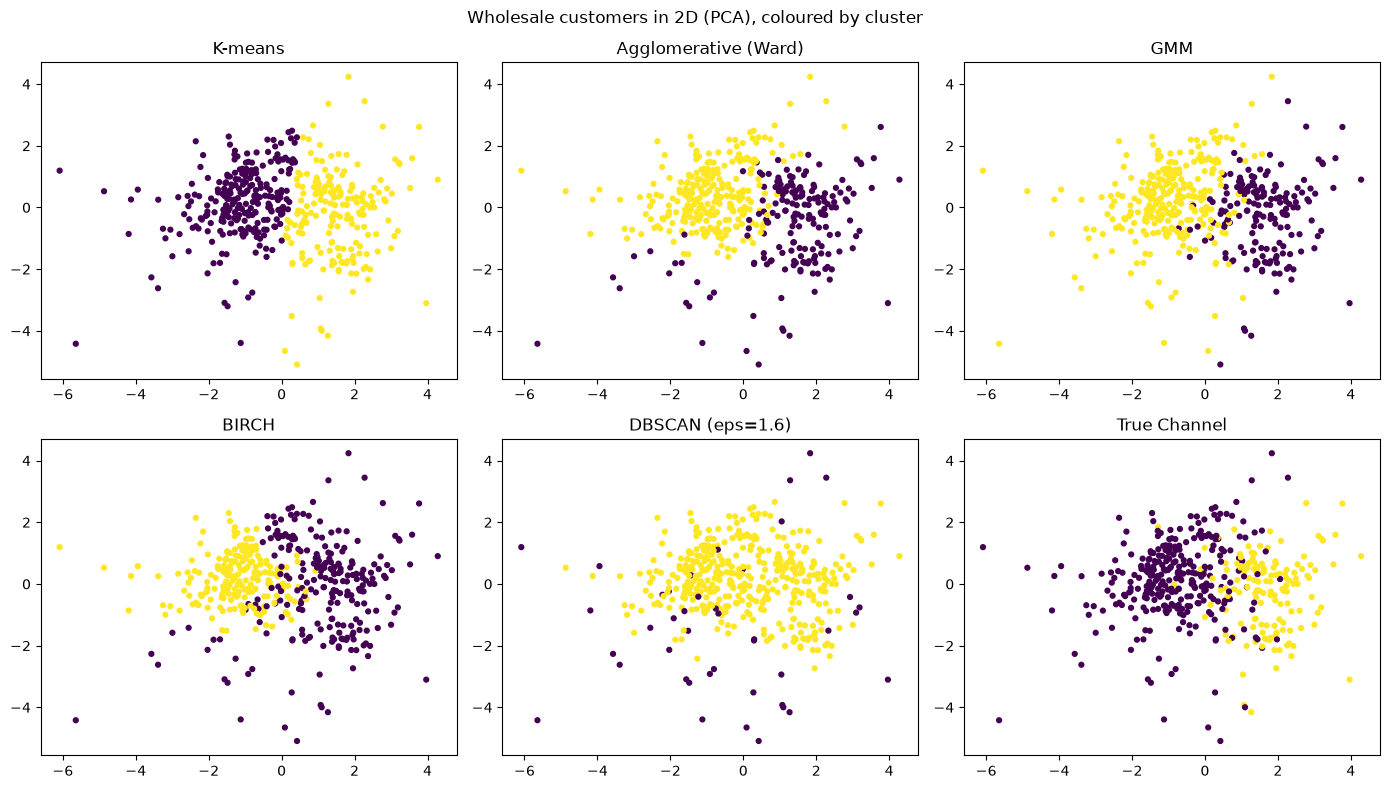

In [20]:
ws_2d = PCA(n_components=2).fit_transform(X_ws)
all_labels = {**results, "DBSCAN (eps=1.6)": db_labels, "True Channel": y_ws}
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (name, labels) in zip(axes.ravel(), all_labels.items()):
    ax.scatter(ws_2d[:, 0], ws_2d[:, 1], c=labels, cmap="viridis", s=12)
    ax.set_title(name)
plt.suptitle("Wholesale customers in 2D (PCA), coloured by cluster")
plt.tight_layout()
plt.show()

### Interpretation: cluster profiles
- **Cluster 0 (252 customers), "fresh-food buyers":** high Fresh (13,973) and Frozen (3,706) spending, but low Grocery (2,919) and Detergents_Paper (492). 244 of them are Horeca (hotels, restaurants and cafés).
- **Cluster 1 (188 customers), "grocery and household buyers":** about 5 times more Grocery (14,697), 4 times more Milk (10,346) and 12 times more Detergents_Paper (6,085). 134 of them are Retail.
- So without seeing the labels, K-means rediscovered the restaurant vs shop split. The 54 Horeca customers in cluster 1 are probably cafés or hotels that buy like shops.
- In the PCA (Principal Component Analysis) plots, K-means, Ward, GMM and BIRCH all cut the cloud in the same left–right direction. Only the colours swap because cluster numbers are arbitrary. DBSCAN makes everything one cluster and marks only the outer points as noise.

# Task 2: Non-linear and Hierarchical Clustering (Forest Cover Type)

## About the dataset
The Forest Cover Type dataset describes 30 m × 30 m land cells in the Roosevelt National Forest in Colorado. It has 581,012 rows and 54 features. There are 10 numeric terrain features (elevation, aspect, slope, distances to water, roads and fire points, and hillshade at 9am, noon and 3pm), 4 wilderness-area columns and 40 soil-type columns (one-hot). The label is the main tree cover type (7 types).

## Goal
I want to see whether non-linear (spectral) and hierarchical clustering can find natural terrain groups, and whether those groups match the tree cover types.


## Step 2.1: Load the data

In [21]:
cov_df = pd.read_csv("covtype.data.gz", header=None)
num_cols = ["Elevation", "Aspect", "Slope", "H_Dist_Hydrology", "V_Dist_Hydrology", "H_Dist_Roadways",
            "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm", "H_Dist_Fire_Points"]
cov_df = cov_df.rename(columns={**dict(enumerate(num_cols)), 54: "Cover_Type"})
print(cov_df.shape)
cov_df.iloc[:, :10].head()

(581012, 55)


,Elevation,Aspect,Slope,H_Dist_Hydrology,V_Dist_Hydrology,H_Dist_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,H_Dist_Fire_Points
0,2596,51,3,258,0,510,221,232,148,6279
1,2590,56,2,212,-6,390,220,235,151,6225
2,2804,139,9,268,65,3180,234,238,135,6121
3,2785,155,18,242,118,3090,238,238,122,6211
4,2595,45,2,153,-1,391,220,234,150,6172


## Step 2.2: Cover type counts (full data)

In [22]:
cover_names = {1: "Spruce/Fir", 2: "Lodgepole Pine", 3: "Ponderosa Pine", 4: "Cottonwood/Willow",
               5: "Aspen", 6: "Douglas-fir", 7: "Krummholz"}
cov_df["Cover_Type"].map(cover_names).value_counts()

Cover_Type
Lodgepole Pine       283301
Spruce/Fir           211840
Ponderosa Pine        35754
Krummholz             20510
Douglas-fir           17367
Aspen                  9493
Cottonwood/Willow      2747
Name: count, dtype: int64

## Step 2.3: Random sample of 5,000 rows

In [23]:
cov_s = cov_df.sample(n=5000, random_state=42)
y_cov = cov_s["Cover_Type"]
y_cov.map(cover_names).value_counts()

Cover_Type
Lodgepole Pine       2397
Spruce/Fir           1841
Ponderosa Pine        324
Krummholz             175
Douglas-fir           150
Aspen                  88
Cottonwood/Willow      25
Name: count, dtype: int64

## Step 2.4: Scale the 10 numeric features

In [24]:
X_cov = StandardScaler().fit_transform(cov_s[num_cols])
print(X_cov.shape)

(5000, 10)


### Interpretation: data and sample
- The full dataset has 581,012 land cells. It is very **imbalanced**: Lodgepole Pine (283,301) and Spruce/Fir (211,840) make up 85% of the data, while Cottonwood/Willow has only 2,747 cells.
- My random sample of 5,000 keeps the same shape (2,397 Lodgepole Pine down to 25 Cottonwood/Willow). Spectral clustering needs a 5,000 × 5,000 similarity graph, and the dendrogram needs about 12.5 million pairwise distances, so the full data would not fit on a laptop.
- I use only the 10 numeric terrain features and scale them, because they have very different units (elevation in metres, aspect in degrees, hillshade from 0 to 255).

## Step 2.5: Spectral clustering for k = 2 to 7

In [25]:
sp_scores = []
for k in range(2, 8):
    labels = SpectralClustering(n_clusters=k, affinity="nearest_neighbors", n_neighbors=15,
                                assign_labels="cluster_qr", random_state=42).fit_predict(X_cov)
    sp_scores.append([k, silhouette_score(X_cov, labels)])
sp_scores = pd.DataFrame(sp_scores, columns=["k", "silhouette"])
sp_scores.round(3)

,k,silhouette
0,2,0.224
1,3,0.150
2,4,0.153
3,5,0.157
4,6,0.146
5,7,0.143


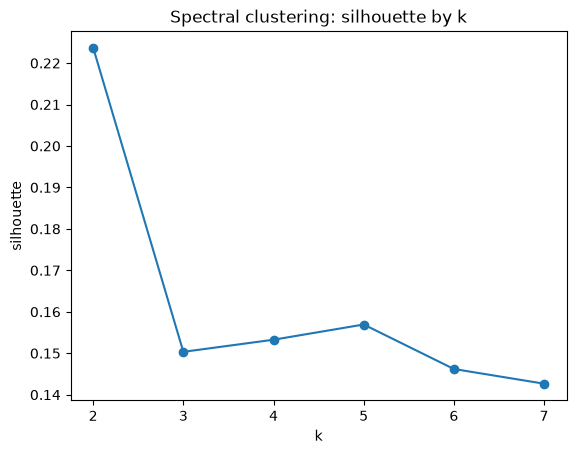

In [26]:
plt.plot(sp_scores["k"], sp_scores["silhouette"], marker="o")
plt.xlabel("k")
plt.ylabel("silhouette")
plt.title("Spectral clustering: silhouette by k")
plt.show()

## Step 2.6: Final spectral clustering (k = 2) and cluster profile

In [27]:
sp_labels = SpectralClustering(n_clusters=2, affinity="nearest_neighbors", n_neighbors=15,
                               assign_labels="cluster_qr", random_state=42).fit_predict(X_cov)
sp_profile = cov_s[num_cols].groupby(sp_labels).mean().round(0).T
sp_profile.columns = [f"cluster {c} (n={n})" for c, n in enumerate(np.bincount(sp_labels))]
sp_profile

,cluster 0 (n=1789),cluster 1 (n=3211)
Elevation,2965.0,2948.0
Aspect,290.0,81.0
Slope,15.0,13.0
H_Dist_Hydrology,290.0,256.0
V_Dist_Hydrology,56.0,41.0
H_Dist_Roadways,2401.0,2289.0
Hillshade_9am,185.0,227.0
Hillshade_Noon,231.0,219.0
Hillshade_3pm,181.0,122.0
H_Dist_Fire_Points,1721.0,2134.0


### Interpretation: spectral clustering
- Silhouette is highest at **k = 2 (0.224)** and stays around 0.14–0.16 for k = 3 to 7, so I choose 2 clusters.
- The two clusters are almost the same in elevation (2,965 m vs 2,948 m), slope and distances. The big difference is **aspect** (the direction the slope faces): 290° (west-facing) vs 81° (east-facing).
- The hillshade columns confirm this. West-facing slopes are brighter at 3pm (181 vs 122), and east-facing slopes are brighter at 9am (227 vs 185).
- So spectral clustering found a real natural split: **east-facing vs west-facing slopes**. One limitation: aspect is circular (0° and 360° are both north), but the model treats it as a straight line.

## Step 2.7: Agglomerative clustering with 4 linkages

In [28]:
rows = []
for link in ["single", "complete", "average", "ward"]:
    labels = AgglomerativeClustering(n_clusters=4, linkage=link).fit_predict(X_cov)
    coph = cophenet(linkage(X_cov, method=link), pdist(X_cov))[0]
    rows.append([link, np.bincount(labels).tolist(), silhouette_score(X_cov, labels), coph])
link_df = pd.DataFrame(rows, columns=["linkage", "sizes (k=4)", "silhouette", "cophenetic_corr"])
link_df.round(3)

,linkage,sizes (k=4),silhouette,cophenetic_corr
0,single,"[4995, 2, 2, 1]",0.175,0.608
1,complete,"[200, 4499, 171, 130]",0.225,0.600
2,average,"[4, 173, 4818, 5]",0.306,0.680
3,ward,"[1047, 2077, 1039, 837]",0.133,0.418


### Interpretation: four linkages
- **Single linkage** puts 4,995 of 5,000 points in one cluster (the "chaining" problem from Lesson 5). **Average** (4,818 in one cluster) and **complete** (4,499) do almost the same.
- Average linkage has the highest silhouette (0.306) and cophenetic correlation (0.680), but this is misleading. It only cuts off a few outliers, which is not useful grouping.
- **Ward** is the only linkage that gives balanced groups (837 to 2,077 points). Its silhouette (0.133) and cophenetic correlation (0.418) are the lowest, because Ward forces round groups out of one big continuous cloud.
- Since I want useful terrain groups, not just outliers, I continue with **Ward**.

## Step 2.8: Ward dendrogram

In [29]:
Z_cov = linkage(X_cov, method="ward")
print("Last 6 merge heights:", Z_cov[-6:, 2].round(1))
cut = (Z_cov[-4, 2] + Z_cov[-3, 2]) / 2   # between the merges that leave 4 and 3 clusters

Last 6 merge heights: [ 53.8  60.8  65.   88.   91.1 125.7]


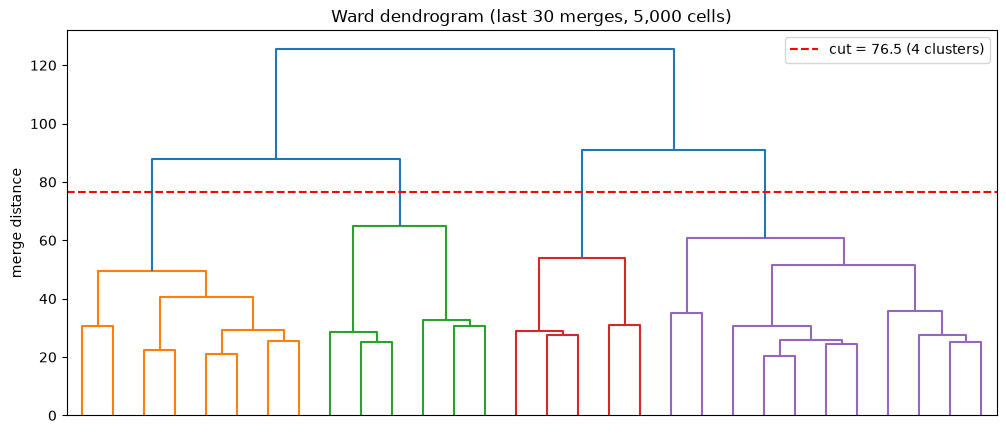

In [30]:
plt.figure(figsize=(12, 5))
dendrogram(Z_cov, truncate_mode="lastp", p=30, no_labels=True)
plt.axhline(cut, color="red", linestyle="--", label=f"cut = {cut:.1f} (4 clusters)")
plt.title("Ward dendrogram (last 30 merges, 5,000 cells)")
plt.ylabel("merge distance")
plt.legend()
plt.show()

## Step 2.9: Ward clusters (4) and their profile

In [31]:
ward_labels = fcluster(Z_cov, t=4, criterion="maxclust") - 1
ward_profile = cov_s[num_cols].groupby(ward_labels).mean().round(0).T
ward_profile.columns = [f"cluster {c} (n={n})" for c, n in enumerate(np.bincount(ward_labels))]
ward_profile

,cluster 0 (n=837),cluster 1 (n=1047),cluster 2 (n=1039),cluster 3 (n=2077)
Elevation,3123.0,2886.0,2747.0,3024.0
Aspect,201.0,303.0,74.0,105.0
Slope,14.0,17.0,18.0,11.0
H_Dist_Hydrology,547.0,187.0,196.0,233.0
V_Dist_Hydrology,120.0,39.0,39.0,24.0
H_Dist_Roadways,2204.0,2242.0,1331.0,2922.0
Hillshade_9am,207.0,178.0,228.0,223.0
Hillshade_Noon,232.0,226.0,207.0,227.0
Hillshade_3pm,157.0,184.0,104.0,136.0
H_Dist_Fire_Points,1642.0,1492.0,1319.0,2708.0


### Interpretation: dendrogram and Ward clusters
- The biggest jump in merge height is from 91.1 to 125.7, which would give 2 clusters (the same east/west split spectral found). The next big jump is from 65.0 to 88.0. I cut there (at 76.5) to get **4 clusters**, which adds more detail.
- **Cluster 0 (837):** high ground (3,123 m), far from water (547 m), mixed aspect.
- **Cluster 1 (1,047):** west-facing (303°), mid elevation, bright in the afternoon.
- **Cluster 2 (1,039):** the **lowest and steepest** cells (2,747 m, slope 18°), east-facing and closest to roads (1,331 m).
- **Cluster 3 (2,077):** high (3,024 m), flat (slope 11°), east-facing and far from roads (2,922 m) and fire points (2,708 m).

## Step 2.10: Compare with the true cover types

In [32]:
print("ARI spectral vs cover type:", round(adjusted_rand_score(y_cov, sp_labels), 3))
print("ARI ward     vs cover type:", round(adjusted_rand_score(y_cov, ward_labels), 3))
pd.crosstab(ward_labels, y_cov.map(cover_names))

ARI spectral vs cover type: 0.002
ARI ward     vs cover type: 0.046


Cover_Type,Aspen,Cottonwood/Willow,Douglas-fir,Krummholz,Lodgepole Pine,Ponderosa Pine,Spruce/Fir
row_0,,,,,,,
0,13,1,4,66,400,30,323
1,12,5,75,20,420,112,403
2,43,19,68,18,522,170,199
3,20,0,3,71,1055,12,916


## Step 2.11: Visualize in 2D (PCA)

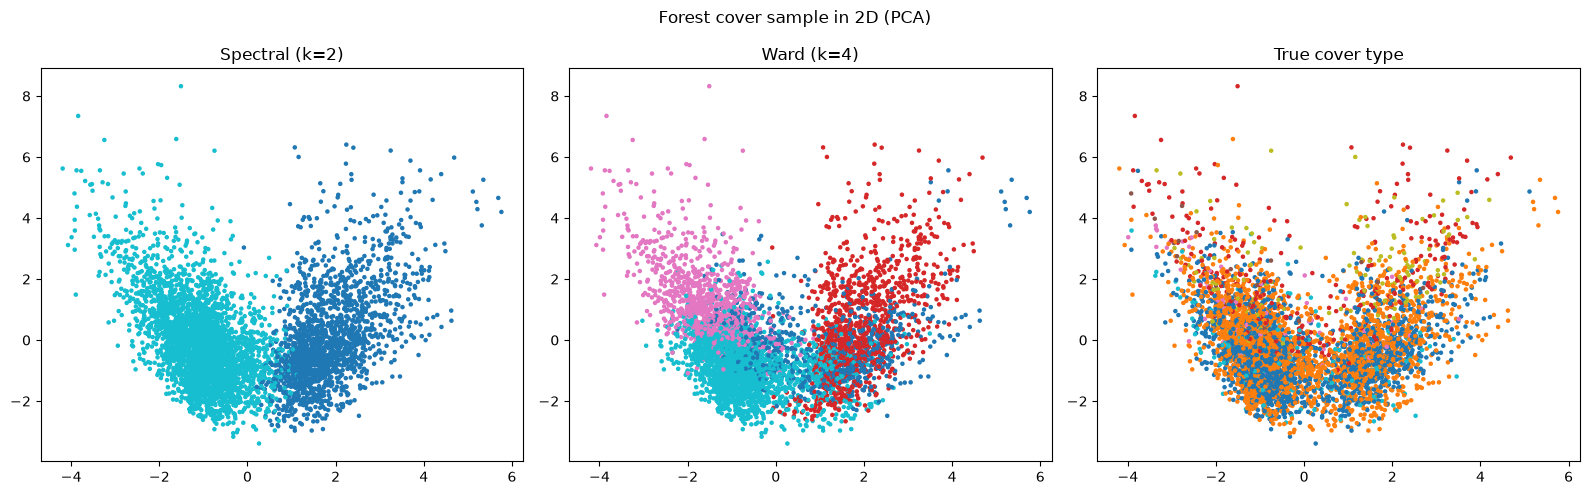

In [33]:
cov_2d = PCA(n_components=2).fit_transform(X_cov)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, labels) in zip(axes, [("Spectral (k=2)", sp_labels), ("Ward (k=4)", ward_labels),
                                     ("True cover type", y_cov)]):
    ax.scatter(cov_2d[:, 0], cov_2d[:, 1], c=labels, cmap="tab10", s=5)
    ax.set_title(name)
plt.suptitle("Forest cover sample in 2D (PCA)")
plt.tight_layout()
plt.show()

### Interpretation: comparison with tree cover types
- The ARI is almost zero for both methods: **0.002 for spectral** and **0.046 for Ward**. The natural terrain groups do **not** match the 7 tree types.
- Ward still finds something meaningful. Cluster 2 (low, steep cells) holds 19 of the 25 Cottonwood/Willow, 43 of the 88 Aspen and 170 of the 324 Ponderosa Pine, the species that grow lower down. Cluster 3 (high and flat) is mostly Spruce/Fir and Lodgepole Pine, with only 12 Ponderosa Pine.
- In the PCA plot, the true cover types are mixed all over the cloud, while the clusters split it by direction and height. Tree type depends on many small things at once (elevation, soil, wilderness area), so clustering on terrain alone mainly finds **slope direction and elevation zones**, not tree species.
- Spectral clustering was helpful because it captured the curved (V-shaped) structure, but non-linear methods cannot find groups that are not separated in the features.

# Task 3: Soft Labels with Fuzzy C-means and GMM (Car Evaluation)

## About the dataset
The Car Evaluation dataset has 1,728 cars described by 6 categorical ratings: buying price, maintenance cost, number of doors, number of persons, luggage boot size and safety. The label is the car's acceptability (unacc, acc, good, vgood).

## Goal
I want to give each car a **soft label**, a degree of belonging to every cluster instead of one hard label, using Fuzzy C-means (FCM) and a Gaussian Mixture Model (GMM). Then I compare how confident each method is.

## Step 3.1: Load the data

In [34]:
car_cols = ["buying", "maint", "doors", "persons", "lug_boot", "safety", "class"]
car_df = pd.read_csv("car.data", header=None, names=car_cols)
print(car_df.shape)
car_df.head()

(1728, 7)


,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


## Step 3.2: Check the structure

In [35]:
print(car_df.drop(columns="class").nunique())
print("Possible combinations:", 4 * 4 * 4 * 3 * 3 * 3)
print("Duplicate rows:", car_df.drop(columns="class").duplicated().sum())
car_df["class"].value_counts()

buying      4
maint       4
doors       4
persons     3
lug_boot    3
safety      3
dtype: int64
Possible combinations: 1728
Duplicate rows: 0


class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64

### Interpretation: data structure
- There are 1,728 cars and **0 duplicates**, and 4 × 4 × 4 × 3 × 3 × 3 = 1,728. This means the dataset is a **complete grid**: every possible combination of the 6 ratings appears exactly once.
- A perfect grid has **no natural clusters**, because the points are spread evenly with no dense areas or gaps. This is an important warning before soft clustering: I should expect very uncertain memberships.
- The label is imbalanced: 1,210 cars are unacceptable (70%), and only 69 are good and 65 very good.

## Step 3.3: Ordinal encoding and scaling

In [36]:
car_order = [["low", "med", "high", "vhigh"], ["low", "med", "high", "vhigh"], ["2", "3", "4", "5more"],
             ["2", "4", "more"], ["small", "med", "big"], ["low", "med", "high"]]
car_X = pd.DataFrame(OrdinalEncoder(categories=car_order).fit_transform(car_df[car_cols[:6]]),
                     columns=car_cols[:6])
X_car = StandardScaler().fit_transform(car_X)
car_X.head()

,buying,maint,doors,persons,lug_boot,safety
0,3.0,3.0,0.0,0.0,0.0,0.0
1,3.0,3.0,0.0,0.0,0.0,1.0
2,3.0,3.0,0.0,0.0,0.0,2.0
3,3.0,3.0,0.0,0.0,1.0,0.0
4,3.0,3.0,0.0,0.0,1.0,1.0


## Step 3.4: Fuzzy C-means function (same as Assignment 6)

In [37]:
def fuzzy_cmeans(X, c, m=2.0, max_iter=1000, tol=1e-5, seed=42):
    rng = np.random.default_rng(seed)
    W = rng.random((X.shape[0], c))
    W = W / W.sum(axis=1, keepdims=True)
    for iteration in range(1, max_iter + 1):
        Wm = W ** m
        centers = (Wm.T @ X) / Wm.sum(axis=0)[:, None]
        d = cdist(X, centers) + 1e-10
        W_new = 1.0 / ((d[:, :, None] / d[:, None, :]) ** (2.0 / (m - 1.0))).sum(axis=2)
        if np.abs(W_new - W).max() < tol:
            W = W_new
            break
        W = W_new
    pc = np.mean(np.sum(W ** 2, axis=1))
    pc_norm = (c * pc - 1) / (c - 1)   # 0 = totally fuzzy, 1 = totally crisp
    return centers, W, pc_norm, iteration

## Step 3.5: Choose the fuzziness m (with c = 4)

In [38]:
for m in [1.1, 1.25, 1.5, 2.0]:
    _, W, pc, it = fuzzy_cmeans(X_car, c=4, m=m)
    print(f"m={m}: normalized PC={pc:.3f}, average max membership={W.max(axis=1).mean():.3f}, iterations={it}")

m=1.1: normalized PC=0.825, average max membership=0.918, iterations=114
m=1.25: normalized PC=0.465, average max membership=0.700, iterations=107
m=1.5: normalized PC=0.007, average max membership=0.297, iterations=1000
m=2.0: normalized PC=0.000, average max membership=0.250, iterations=18


### Interpretation: choosing the fuzziness m
- **m = 2.0** (the usual default) completely **collapses**: the normalized PC (Partition Coefficient) is 0.000 and every car has membership 0.25 in all 4 clusters. On this evenly spread grid, all centres move to the middle of the data.
- **m = 1.5** almost collapses too (PC 0.007) and did not converge in 1,000 iterations.
- **m = 1.1** is almost a hard clustering (average max membership 0.918), so I would lose the "soft" idea.
- **m = 1.25** is the balance: clear structure (PC 0.465) but still soft (average max membership 0.70). I use **m = 1.25**. This was a surprising finding: the default m = 2 does not work on every dataset.

## Step 3.6: Choose the number of clusters c (with m = 1.25)

In [39]:
for c in range(2, 7):
    _, W, pc, it = fuzzy_cmeans(X_car, c=c, m=1.25)
    print(f"c={c}: normalized PC={pc:.3f}, silhouette={silhouette_score(X_car, W.argmax(axis=1)):.3f}, iterations={it}")

c=2: normalized PC=0.433, silhouette=0.131, iterations=80
c=3: normalized PC=0.427, silhouette=0.117, iterations=433
c=4: normalized PC=0.465, silhouette=0.123, iterations=107
c=5: normalized PC=0.472, silhouette=0.122, iterations=332
c=6: normalized PC=0.487, silhouette=0.122, iterations=1000


### Interpretation: choosing c
- The normalized PC is almost flat (0.427 to 0.487), and silhouette is very low for every c (0.117 to 0.131). As I expected for a grid, **no number of clusters is clearly natural**.
- I choose **c = 4** because it converges quickly (107 iterations), has a reasonable PC (0.465) and matches the 4 acceptability levels from domain knowledge. The labels were only used to choose the number, not to fit the model. c = 3 and c = 6 needed 433 and 1,000 iterations, which shows they are less stable.

## Step 3.7: Final FCM (c = 4, m = 1.25)

In [40]:
fcm_centers, fcm_W, fcm_pc, _ = fuzzy_cmeans(X_car, c=4, m=1.25)
fcm_labels = fcm_W.argmax(axis=1)
memb = pd.DataFrame(fcm_W.round(3), columns=[f"cluster_{j}" for j in range(4)])
memb["max_membership"] = fcm_W.max(axis=1).round(3)
memb.head(8)

,cluster_0,cluster_1,cluster_2,cluster_3,max_membership
0,0.046,0.049,0.046,0.858,0.858
1,0.039,0.135,0.123,0.703,0.703
2,0.039,0.330,0.301,0.330,0.330
3,0.123,0.135,0.039,0.703,0.703
4,0.076,0.424,0.076,0.424,0.424
5,0.039,0.703,0.123,0.135,0.703
6,0.301,0.330,0.039,0.330,0.330
7,0.123,0.703,0.039,0.135,0.703


## Step 3.8: FCM cluster profiles

In [41]:
display(car_X.groupby(fcm_labels).mean().round(2).assign(size=np.bincount(fcm_labels)))
pd.crosstab(fcm_labels, car_df["class"])

,buying,maint,doors,persons,lug_boot,safety,size
0,0.61,1.50,1.57,1.15,1.56,0.44,432
1,2.42,1.58,1.39,0.92,1.52,1.52,462
2,0.61,1.50,1.43,0.85,0.44,1.56,432
3,2.35,1.41,1.62,1.09,0.40,0.40,402


class,acc,good,unacc,vgood
row_0,,,,
0,76,39,299,18
1,143,0,303,16
2,133,30,238,31
3,32,0,370,0


### Interpretation: FCM memberships and profiles
- The memberships are truly soft. Car 2 has 0.330 / 0.301 / 0.330 across three clusters, and car 4 is split 0.424 / 0.424 between two. These cars sit exactly between cluster centres on the grid.
- FCM grouped the cars by **price and safety/boot size**:
  - Cluster 0: cheap to buy (0.61), big boot, low safety (432 cars)
  - Cluster 1: expensive (2.42), high safety (462 cars)
  - Cluster 2: cheap, small boot, high safety (432 cars)
  - Cluster 3: expensive, small boot, low safety (402 cars)
- Cluster 3 (expensive and unsafe) is 92% unacceptable (370 of 402), which makes sense. The clusters are very balanced in size (402–462), which is what you expect from evenly spread grid data.

## Step 3.9: GMM: choose the number of components with BIC

In [42]:
car_bic = [GaussianMixture(n_components=k, n_init=3, random_state=42).fit(X_car).bic(X_car) for k in range(1, 9)]
pd.DataFrame({"k": range(1, 9), "BIC": np.round(car_bic)})

,k,BIC
0,1,29624.0
1,2,29409.0
2,3,22295.0
3,4,17607.0
4,5,14540.0
5,6,13205.0
6,7,3917.0
7,8,4282.0


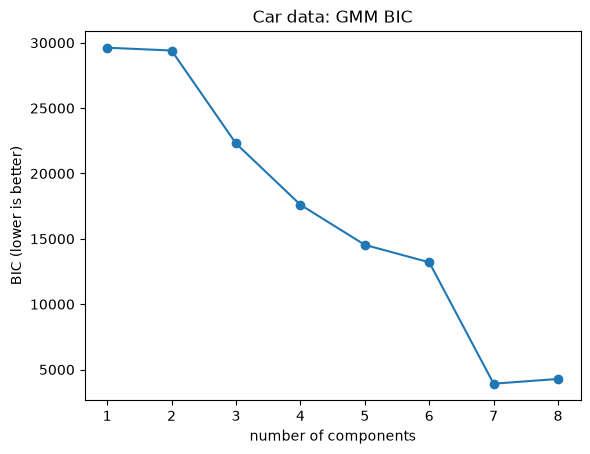

In [43]:
plt.plot(range(1, 9), car_bic, marker="o")
plt.xlabel("number of components")
plt.ylabel("BIC (lower is better)")
plt.title("Car data: GMM BIC")
plt.show()

### Interpretation: GMM BIC
- BIC keeps falling, from 29,624 at k = 1 to 3,917 at k = 7, and has no clear minimum.
- This happens because the data only has 3–4 distinct values per feature. More components let the GMM put very narrow "spikes" on exact values, and BIC rewards this even though it is not a real cluster. I saw the same problem with one-hot columns in Assignment 6.
- So BIC is not reliable here, and I use **4 components**, the same as FCM, so the two methods can be compared directly.

## Step 3.10: Final GMM (4 components) and its probabilities

In [44]:
car_gmm = GaussianMixture(n_components=4, n_init=5, random_state=42).fit(X_car)
gmm_P = car_gmm.predict_proba(X_car)
gmm_car_labels = gmm_P.argmax(axis=1)
probs = pd.DataFrame(gmm_P.round(3), columns=[f"comp_{j}" for j in range(4)])
probs["max_prob"] = gmm_P.max(axis=1).round(3)
probs.head(8)

,comp_0,comp_1,comp_2,comp_3,max_prob
0,0.000,0.0,0.0,1.000,1.000
1,0.000,0.0,0.0,1.000,1.000
2,0.113,0.0,0.0,0.887,0.887
3,0.000,0.0,0.0,1.000,1.000
4,0.000,0.0,0.0,1.000,1.000
5,0.113,0.0,0.0,0.887,0.887
6,0.000,0.0,0.0,1.000,1.000
7,0.000,0.0,0.0,1.000,1.000


## Step 3.11: GMM cluster profiles

In [45]:
display(car_X.groupby(gmm_car_labels).mean().round(2).assign(size=np.bincount(gmm_car_labels)))
pd.crosstab(gmm_car_labels, car_df["class"])

,buying,maint,doors,persons,lug_boot,safety,size
0,1.5,1.5,1.5,1.5,1.0,2.0,384
1,2.5,1.5,1.5,1.5,1.0,0.5,384
2,0.5,1.5,1.5,1.5,1.0,0.5,384
3,1.5,1.5,1.5,0.0,1.0,1.0,576


class,acc,good,unacc,vgood
row_0,,,,
0,204,30,85,65
1,65,0,319,0
2,115,39,230,0
3,0,0,576,0


### Interpretation: GMM probabilities and profiles
- GMM is very **confident**: most cars have probability 1.000 for one component, and the lowest maximum probability shown is 0.887.
- GMM split the cars on **single features**, mostly safety and persons:
  - Component 0: high safety (384 cars); it contains all 65 very good cars
  - Component 1: expensive and low safety (384 cars)
  - Component 2: cheap and low safety (384 cars)
  - Component 3: **2-seater cars** (persons = 0, 576 cars), and **all 576 are unacceptable**
- This last component is a nice finding: every 2-seater car in the dataset is rated unacceptable. The GMM found this rule without seeing the labels.

## Step 3.12: Compare FCM and GMM confidence

In [46]:
conf = pd.DataFrame({
    "method": ["FCM (m=1.25)", "GMM"],
    "average max membership": [fcm_W.max(axis=1).mean(), gmm_P.max(axis=1).mean()],
    "share above 0.9": [(fcm_W.max(axis=1) > 0.9).mean(), (gmm_P.max(axis=1) > 0.9).mean()],
    "share below 0.5": [(fcm_W.max(axis=1) < 0.5).mean(), (gmm_P.max(axis=1) < 0.5).mean()],
})
display(conf.round(3))
print("ARI between FCM and GMM hard labels:", round(adjusted_rand_score(fcm_labels, gmm_car_labels), 3))

,method,average max membership,share above 0.9,share below 0.5
0,FCM (m=1.25),0.700,0.176,0.222
1,GMM,0.981,0.889,0.000


ARI between FCM and GMM hard labels: 0.179


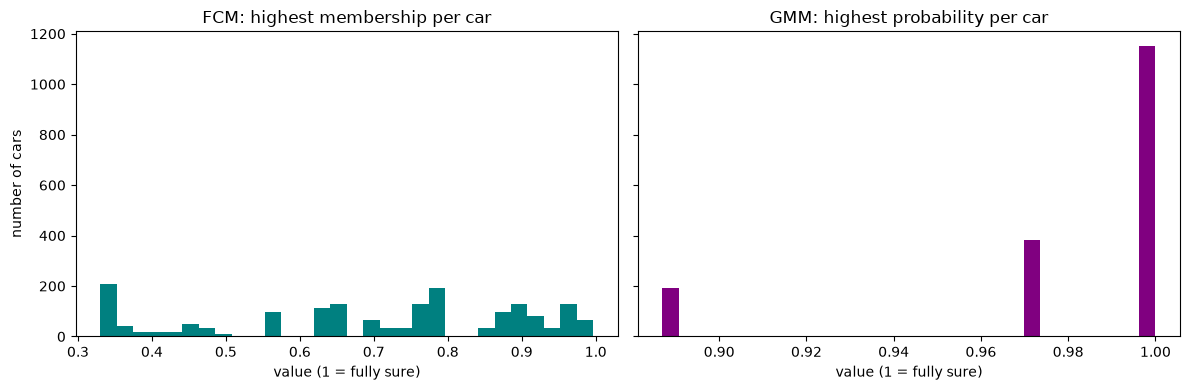

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].hist(fcm_W.max(axis=1), bins=30, color="teal")
axes[0].set_title("FCM: highest membership per car")
axes[1].hist(gmm_P.max(axis=1), bins=30, color="purple")
axes[1].set_title("GMM: highest probability per car")
for ax in axes:
    ax.set_xlabel("value (1 = fully sure)")
axes[0].set_ylabel("number of cars")
plt.tight_layout()
plt.show()

### Interpretation: FCM vs GMM
- **FCM is much softer:** average max membership 0.700, only 17.6% of cars above 0.9, and 22.2% below 0.5 (no cluster gets even half of the membership).
- **GMM is almost hard:** average max probability 0.981, 88.9% of cars above 0.9, and no car below 0.5. In the histogram, the GMM probabilities only take three values (about 0.89, 0.97 and 1.00), because the cars sit on exact grid points.
- The two methods found **different groupings** (ARI 0.179 between them). FCM groups cars by distance in all 6 features at once. GMM fits a probability model and cuts along single features (safety, persons).
- For this grid data, I think **FCM's uncertainty is more honest**, because there really are no natural clusters. GMM's 99% confidence is **overconfidence** caused by the discrete values, not proof of real groups.

# Task 4: Anomaly Detection with Density Estimation (Gas Sensor Array Drift)

## About the dataset
The Gas Sensor Array Drift dataset has 13,910 measurements from 16 chemical sensors exposed to 6 gases (ammonia, acetaldehyde, acetone, ethylene, ethanol and toluene). Each sensor gives 8 features, so there are 128 features in total. The data was recorded in 10 batches over 36 months. Batch 1 = months 1–2, batch 2 = months 3–10, batch 3 = months 11–13, batch 4 = months 14–15, batch 5 = month 16, batch 6 = months 17–20, batch 7 = month 21, batch 8 = months 22–23, batch 9 = months 24–30 and batch 10 = month 36. Over time the sensors age and their readings **drift**.

## Goal
I treat the first two batches (months 1–10) as "normal" and learn their density. Then I score every later batch. If a measurement has a very low density under the normal model, I flag it as an anomaly. If drift is real, the share of anomalies should grow over time.

## Step 4.1: Load the 10 batches

In [48]:
gas_X, gas_y, gas_batch = [], [], []
for b in range(1, 11):
    X_b, y_b = load_svmlight_file(f"gas_data/batch{b}.dat", n_features=128)
    gas_X.append(X_b.toarray())
    gas_y.append(y_b)
    gas_batch.append(np.full(len(y_b), b))
gas_X, gas_y, gas_batch = np.vstack(gas_X), np.concatenate(gas_y), np.concatenate(gas_batch)
print(gas_X.shape)

(13910, 128)


## Step 4.2: Rows per batch and value range

In [49]:
print("Rows per batch:", dict(zip(range(1, 11), np.bincount(gas_batch)[1:])))
print("Min value:", gas_X.min().round(1), " Max value:", gas_X.max().round(1))

Rows per batch: {1: np.int64(445), 2: np.int64(1244), 3: np.int64(1586), 4: np.int64(161), 5: np.int64(197), 6: np.int64(2300), 7: np.int64(3613), 8: np.int64(294), 9: np.int64(470), 10: np.int64(3600)}
Min value: -23660.6  Max value: 670687.3


## Step 4.3: Signed log transform

In [50]:
gas_log = np.sign(gas_X) * np.log1p(np.abs(gas_X))
print("Min after log:", gas_log.min().round(2), " Max after log:", gas_log.max().round(2))

Min after log: -10.07  Max after log: 13.42


### Interpretation: data and log transform
- I loaded 13,910 measurements with 128 features. The batches have very different sizes, from 161 rows (batch 4) to 3,613 rows (batch 7).
- The raw values range from −23,661 to 670,687, a huge spread with some very extreme readings. The **signed log** (sign × log(1 + |x|)) brings this down to −10.1 to 13.4 while keeping negative values negative, the same trick I used on bank balance in Assignment 6.
- I tested this first: without the log, a few extreme values dominate the scaling and the drift pattern is hidden.

## Step 4.4: Normal data = batches 1–2, split into train and validation

In [51]:
normal = gas_log[gas_batch <= 2]
gas_train, gas_val = train_test_split(normal, test_size=0.2, random_state=42)
print("Train:", gas_train.shape, " Validation:", gas_val.shape)

Train: (1351, 128)  Validation: (338, 128)


## Step 4.5: Scale and PCA (fitted on normal training data only)

In [52]:
gas_scaler = StandardScaler().fit(gas_train)
gas_pca = PCA(n_components=10).fit(gas_scaler.transform(gas_train))
to_pca = lambda A: gas_pca.transform(gas_scaler.transform(A))
Z_train, Z_val, Z_all = to_pca(gas_train), to_pca(gas_val), to_pca(gas_log)
print("Components kept:", gas_pca.n_components_, " Variance explained:", gas_pca.explained_variance_ratio_.sum().round(3))

Components kept: 10  Variance explained: 0.976


## Step 4.6: KDE: choose bandwidth with cross-validation

In [53]:
grid = GridSearchCV(KernelDensity(kernel="gaussian"), {"bandwidth": np.logspace(-1, 1, 15)}, cv=5).fit(Z_train)
kde = grid.best_estimator_
print("Best bandwidth:", round(grid.best_params_["bandwidth"], 3))

Best bandwidth: 0.72


## Step 4.7: GMM: choose the number of components with BIC

In [54]:
gas_bic = [GaussianMixture(n_components=k, n_init=3, random_state=42).fit(Z_train).bic(Z_train) for k in range(1, 11)]
best_k = int(np.argmin(gas_bic)) + 1
gas_gmm = GaussianMixture(n_components=best_k, n_init=3, random_state=42).fit(Z_train)
print("BIC:", np.round(gas_bic))
print("Best number of components:", best_k)

BIC: [56368. 42752. 29990. 26475. 23233. 21783. 17360. 15435. 17677. 16305.]
Best number of components: 8


## Step 4.8: Histogram-based density

In [55]:
n_bins = 20
edges = [np.histogram_bin_edges(Z_train[:, j], bins=n_bins) for j in range(Z_train.shape[1])]

def hist_score(Z):
    # sum of log densities from one histogram per PCA component (outside the range = almost zero density)
    score = np.zeros(len(Z))
    for j, e in enumerate(edges):
        h, _ = np.histogram(Z_train[:, j], bins=e, density=True)
        idx = np.clip(np.digitize(Z[:, j], e) - 1, 0, n_bins - 1)
        inside = (Z[:, j] >= e[0]) & (Z[:, j] <= e[-1])
        score += np.log(np.where(inside, h[idx], 0) + 1e-6)
    return score

### Interpretation: density models
- Batches 1–2 (months 1–10) give 1,689 normal measurements: 1,351 for training and 338 for validation.
- I reduced 128 features to **10 PCA components**, which keep **97.6%** of the variance. Density estimation works poorly in 128 dimensions (the curse of dimensionality), so this step matters. The scaler and PCA were fitted on normal training data only.
- **KDE (Kernel Density Estimation):** cross-validation chose a bandwidth of 0.72.
- **GMM:** BIC is lowest at **8 components** (15,435), then goes up at 9.
- **Histogram:** 20 bins per component, adding the log densities. This assumes the components are independent, which is true for PCA components in a linear sense.

## Step 4.9: Threshold on validation data and anomaly rate by batch

In [56]:
models = {"KDE": kde.score_samples, "GMM": gas_gmm.score_samples, "Histogram": hist_score}
rates = {}
for name, score in models.items():
    threshold = np.percentile(score(Z_val), 2)   # 2% of normal validation points fall below
    flags = score(Z_all) < threshold
    rates[name] = [flags[gas_batch == b].mean() * 100 for b in range(1, 11)]
rate_df = pd.DataFrame(rates, index=pd.Index(range(1, 11), name="batch")).round(1)
rate_df["month"] = ["1-2", "3-10", "11-13", "14-15", "16", "17-20", "21", "22-23", "24-30", "36"]
rate_df

,KDE,GMM,Histogram,month
batch,,,,
1,0.4,0.9,2.5,1-2
2,0.4,1.1,2.7,3-10
3,22.8,24.4,18.7,11-13
4,44.1,54.7,48.4,14-15
5,16.2,52.3,30.5,16
6,61.6,73.2,70.8,17-20
7,87.4,75.5,62.4,21
8,100.0,86.7,82.7,22-23
9,96.2,77.2,78.9,24-30


## Step 4.10: Plot anomaly rate over time

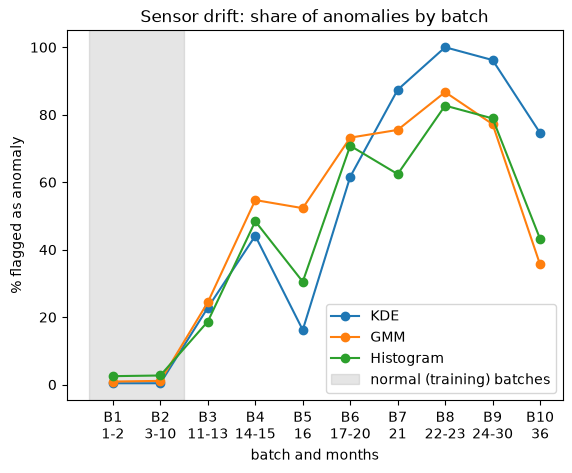

In [57]:
for name in models:
    plt.plot(rate_df.index, rate_df[name], marker="o", label=name)
plt.axvspan(0.5, 2.5, color="grey", alpha=0.2, label="normal (training) batches")
plt.xticks(rate_df.index, [f"B{b}\n{m}" for b, m in zip(rate_df.index, rate_df["month"])])
plt.xlabel("batch and months")
plt.ylabel("% flagged as anomaly")
plt.title("Sensor drift: share of anomalies by batch")
plt.legend()
plt.show()

## Step 4.11: KDE log-density by batch

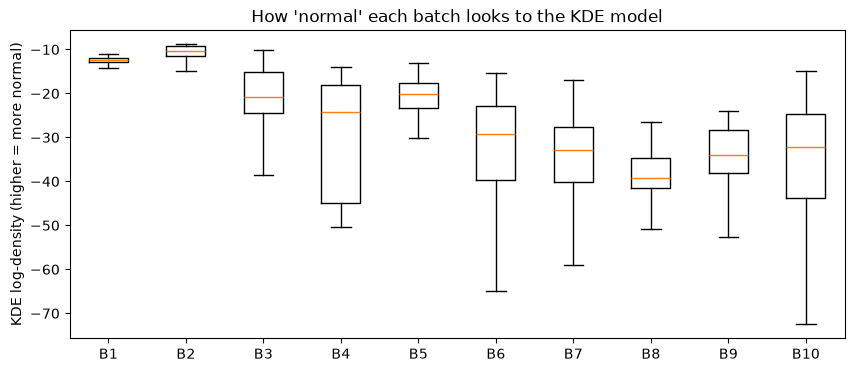

In [58]:
kde_all = kde.score_samples(Z_all)
plt.figure(figsize=(10, 4))
plt.boxplot([kde_all[gas_batch == b] for b in range(1, 11)], showfliers=False)
plt.xticks(range(1, 11), [f"B{b}" for b in range(1, 11)])
plt.ylabel("KDE log-density (higher = more normal)")
plt.title("How 'normal' each batch looks to the KDE model")
plt.show()

### Interpretation: drift detection
- The threshold is the lowest 2% of normal validation scores, so in the normal batches only **0.4–2.7%** are flagged, close to the expected 2%. The models are not over-flagging normal data.
- After month 10 the anomaly rate **jumps**: batch 3 (months 11–13) is 19–24% for all three models, and by batches 6–9 (months 17–30) it is **62–100%**. Batch 8 (months 22–23) is the worst: 100% with KDE, 87% with GMM and 83% with Histogram.
- All three models show the **same trend**, so the result is not caused by one method. The box plot shows the same thing: the median KDE log-density drops from about −11 in batches 1–2 to about −40 in batch 8.
- Batch 10 (month 36) is lower again (36–75%). One possible reason is that the sensors were reset or recalibrated before the last batch, but I cannot confirm this from the data.
- **KDE** is the most sensitive model because it follows the exact shape of the normal data. **GMM** and **Histogram** are smoother and flag fewer points. This shows that a model trained once on early sensor data would fail after about a year, and the sensors would need to be recalibrated or the model retrained.

# Task 5: PCA with Neural Networks (Human Activity Recognition)

## About the dataset
The Human Activity Recognition (HAR) dataset was recorded with a smartphone on the waist of 30 volunteers. It has 561 features from the accelerometer and gyroscope signals (means, standard deviations, energies, frequencies and more). It comes split into 7,352 training rows and 2,947 test rows. The label is one of 6 activities: walking, walking upstairs, walking downstairs, sitting, standing and lying.

## Goal
I want to compress the 561 features into a few numbers. I compare three methods:
- **PCA**, the classic linear method
- A **linear autoencoder**, a neural network with no activation functions, which in theory learns the same subspace as PCA
- A **non-linear autoencoder** with ReLU layers, which can learn curved patterns

I compare them by reconstruction error on the test set and by how well the 2D codes separate the activities.

## Step 5.1: Load the training and test data

In [59]:
har_path = "UCI HAR Dataset/"
har_X_train = np.loadtxt(har_path + "train/X_train.txt")
har_X_test = np.loadtxt(har_path + "test/X_test.txt")
print(har_X_train.shape, har_X_test.shape)

(7352, 561) (2947, 561)


## Step 5.2: Activity labels

In [60]:
activities = pd.read_csv(har_path + "activity_labels.txt", sep=" ", header=None, index_col=0)[1].to_dict()
har_y_test = np.loadtxt(har_path + "test/y_test.txt", dtype=int)
pd.Series(har_y_test).map(activities).value_counts()

LAYING                537
STANDING              532
WALKING               496
SITTING               491
WALKING_UPSTAIRS      471
WALKING_DOWNSTAIRS    420
Name: count, dtype: int64

## Step 5.3: Scale (fitted on training data only)

In [61]:
har_scaler = StandardScaler().fit(har_X_train)
A_train = har_scaler.transform(har_X_train)
A_test = har_scaler.transform(har_X_test)

## Step 5.4: PCA with 2 and 10 components

In [62]:
for k in [2, 10]:
    pca_k = PCA(n_components=k).fit(A_train)
    recon = pca_k.inverse_transform(pca_k.transform(A_test))
    print(f"PCA {k}: variance explained={pca_k.explained_variance_ratio_.sum():.3f}, test MSE={mean_squared_error(A_test, recon):.4f}")

PCA 2: variance explained=0.574, test MSE=0.3917
PCA 10: variance explained=0.708, test MSE=0.2880


### Interpretation: PCA baseline
- 2 components keep **57.4%** of the variance and 10 components keep **70.8%**. The first two components carry a lot of the information, but the rest is spread over many small directions.
- The test **MSE (Mean Squared Error)** of the rebuilt features is 0.392 with 2 components and 0.288 with 10. Because the data is standardized, 0.288 means about 29% of the variance is lost.

## Step 5.5: Autoencoder builder

In [63]:
def build_autoencoder(code_size, hidden=(), activation=None):
    keras.utils.set_random_seed(42)
    inputs = keras.Input(shape=(561,))
    x = inputs
    for units in hidden:
        x = layers.Dense(units, activation=activation)(x)
    code = layers.Dense(code_size, name="code")(x)          # linear bottleneck
    x = code
    for units in reversed(hidden):
        x = layers.Dense(units, activation=activation)(x)
    outputs = layers.Dense(561)(x)
    autoencoder = keras.Model(inputs, outputs)
    autoencoder.compile(optimizer="adam", loss="mse")
    return autoencoder, keras.Model(inputs, code)

early_stop = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)

## Step 5.6: Train the linear autoencoder (561 → 10 → 561)

In [64]:
lin_ae, lin_enc = build_autoencoder(code_size=10)
lin_hist = lin_ae.fit(A_train, A_train, epochs=50, batch_size=128, validation_split=0.1,
                      callbacks=[early_stop], verbose=0)
print("Epochs trained:", len(lin_hist.history["loss"]))

Epochs trained: 50


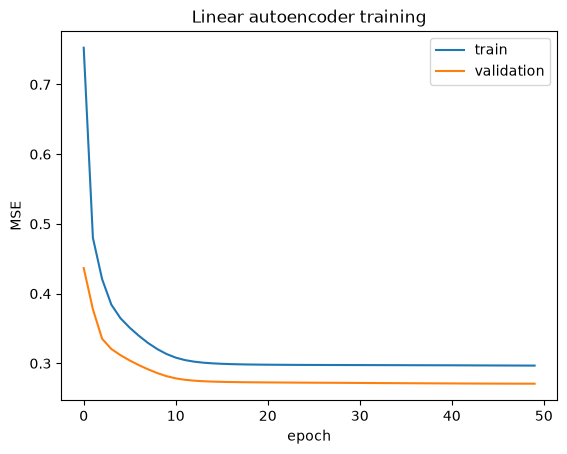

In [65]:
plt.plot(lin_hist.history["loss"], label="train")
plt.plot(lin_hist.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.title("Linear autoencoder training")
plt.legend()
plt.show()

## Step 5.7: Linear autoencoder vs PCA

In [66]:
pca10 = PCA(n_components=10).fit(A_train)
pca10_mse = mean_squared_error(A_test, pca10.inverse_transform(pca10.transform(A_test)))
lin_mse = mean_squared_error(A_test, lin_ae.predict(A_test, verbose=0))
print(f"PCA (10) test MSE:                {pca10_mse:.4f}")
print(f"Linear autoencoder (10) test MSE: {lin_mse:.4f}")

# Does the autoencoder learn the same subspace? Predict PCA scores from the autoencoder codes.
lin_codes = lin_enc.predict(A_test, verbose=0)
r2 = LinearRegression().fit(lin_codes, pca10.transform(A_test)).score(lin_codes, pca10.transform(A_test))
print(f"R² of PCA scores explained by autoencoder codes: {r2:.3f}")

PCA (10) test MSE:                0.2880
Linear autoencoder (10) test MSE: 0.2892
R² of PCA scores explained by autoencoder codes: 0.971


### Interpretation: linear autoencoder vs PCA
- The linear autoencoder trained for all 50 epochs, and the training and validation loss curves stay close (no overfitting).
- Its test MSE (0.2892) is **almost identical** to PCA (0.2880), only 0.4% worse.
- The R² of **0.971** means the 10 autoencoder codes explain 97% of the 10 PCA scores. So the network learned **the same subspace as PCA**, just with rotated and scaled axes. This matches the theory: a neural network with no activation functions and MSE loss learns PCA.
- PCA is still slightly better and much faster, because it finds the exact best solution in one step, while the network has to approach it with gradient descent.

## Step 5.8: Train the non-linear autoencoder (561 → 256 → 64 → 10 → 64 → 256 → 561)

In [67]:
nl_ae, nl_enc = build_autoencoder(code_size=10, hidden=(256, 64), activation="relu")
nl_hist = nl_ae.fit(A_train, A_train, epochs=50, batch_size=128, validation_split=0.1,
                    callbacks=[early_stop], verbose=0)
nl_mse = mean_squared_error(A_test, nl_ae.predict(A_test, verbose=0))
print("Epochs trained:", len(nl_hist.history["loss"]))
print(f"Non-linear autoencoder (10) test MSE: {nl_mse:.4f}")

Epochs trained: 37
Non-linear autoencoder (10) test MSE: 0.2426


### Interpretation: non-linear autoencoder
- The non-linear autoencoder with ReLU layers stopped early at epoch 42 (early stopping kept the best weights).
- Its test MSE is **0.2425**, which is **16% lower** than PCA (0.2880) with the same 10 codes. The extra layers let it learn curved patterns in the sensor data that a straight-line method cannot capture.

## Step 5.9: 2D codes from all three methods

In [68]:
har_2d = {"PCA": PCA(n_components=2).fit(A_train).transform(A_test)}
for name, hidden, act in [("Linear AE", (), None), ("Non-linear AE", (256, 64), "relu")]:
    ae2, enc2 = build_autoencoder(code_size=2, hidden=hidden, activation=act)
    ae2.fit(A_train, A_train, epochs=50, batch_size=128, validation_split=0.1, callbacks=[early_stop], verbose=0)
    har_2d[name] = enc2.predict(A_test, verbose=0)
    print(f"{name} 2D test MSE: {mean_squared_error(A_test, ae2.predict(A_test, verbose=0)):.4f}")
for name, Z in har_2d.items():
    print(f"{name}: silhouette by activity = {silhouette_score(Z, har_y_test):.3f}")

Linear AE 2D test MSE: 0.3923
Non-linear AE 2D test MSE: 0.3395
PCA: silhouette by activity = 0.030
Linear AE: silhouette by activity = 0.027
Non-linear AE: silhouette by activity = 0.137


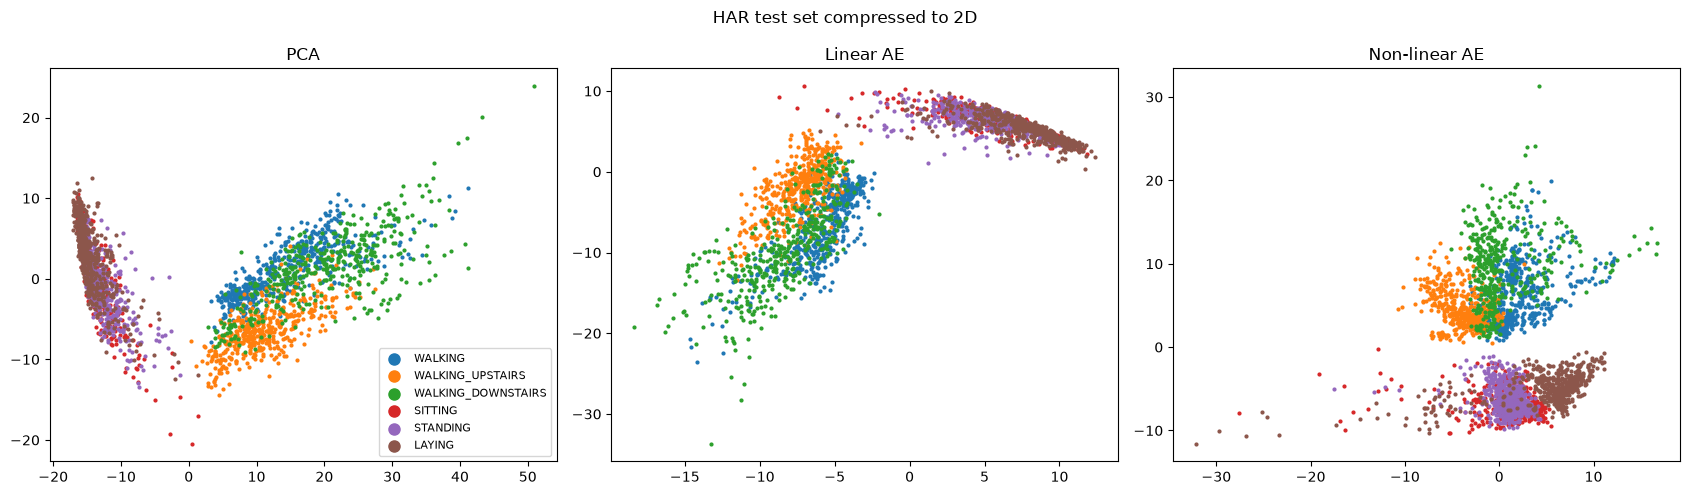

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, Z) in zip(axes, har_2d.items()):
    for a in range(1, 7):
        ax.scatter(Z[har_y_test == a, 0], Z[har_y_test == a, 1], s=4, label=activities[a])
    ax.set_title(name)
axes[0].legend(markerscale=4, fontsize=8)
plt.suptitle("HAR test set compressed to 2D")
plt.tight_layout()
plt.show()

### Interpretation: 2D comparison
- With only 2 codes, the non-linear autoencoder again rebuilds the data best (MSE 0.339 vs 0.392 for both PCA and the linear autoencoder).
- The silhouette by activity is **0.129 for the non-linear autoencoder**, compared with only 0.030 for PCA and 0.027 for the linear autoencoder.
- In the plots, all three methods split **moving activities** (walking, upstairs, downstairs) from **still activities** (sitting, standing, lying). PCA and the linear autoencoder look the same (rotated), with the activities overlapping inside each group. The non-linear autoencoder separates the groups more clearly. Walking upstairs has its own area, and lying starts to separate from sitting and standing.
- Sitting and standing still overlap in every method. The phone on the waist hardly moves in either position, so they are naturally hard to tell apart.

# Final Conclusion

## What I did
I applied the main unsupervised methods from this course to five real datasets, without ever using the labels to fit a model.

## Key findings
- **Task 1 (Wholesale):** All methods agreed on **2 natural groups**. K-means gave the cleanest clusters (silhouette 0.290), and GMM matched the real Horeca vs Retail channel best (ARI 0.622). DBSCAN showed the data is one dense cloud, so it found outliers instead of groups.
- **Task 2 (Cover Type):** Spectral clustering found **east-facing vs west-facing slopes**, and Ward found 4 terrain zones. These groups did not match tree types (ARI below 0.05), but the low, steep zone held most of the rare low-elevation species. Single and average linkage only separated a few outliers.
- **Task 3 (Car):** The data is a **complete grid**, so it has no natural clusters. FCM with the default m = 2 collapsed, and only m = 1.25 worked. FCM gave honest soft memberships (average 0.70), while GMM was overconfident (0.98) because of the discrete values. GMM still found that every 2-seater car is unacceptable.
- **Task 4 (Gas Sensor):** Density models trained on months 1–10 flagged only about 2% of normal data but **62–100% of the data from months 17–30**. All three models (KDE, GMM, Histogram) agreed, which shows strong sensor drift.
- **Task 5 (HAR):** The linear autoencoder learned the **same subspace as PCA** (R² 0.971, almost the same MSE). The non-linear autoencoder reduced the error by 16% and separated the activities better in 2D.

## What I learned
- Preprocessing changes everything: log transforms for skewed spending and sensor data, scaling, and correct ordinal encoding.
- One metric is never enough. Silhouette, BIC and cluster sizes sometimes disagree, and a high score can be misleading (for example, average linkage only cutting off outliers).
- Sometimes the honest result is that **there are no natural clusters** (Car) or that **clusters do not match the labels** (Cover Type), and that is a valid finding.
- Neural networks only beat classic methods when they are allowed to be non-linear.

## Limitations
- Task 2 used a 5,000-row sample, and aspect was treated as a straight line even though it is circular.
- In Task 4, the threshold (2%) and the number of PCA components were my choices. Different choices would change the exact rates, but not the trend.
- Autoencoder results can change slightly between computers because of random weight initialization and different processors.